# Retail Growth and Profitability Comparison - Simple Version

This notebook compares sales growth and operating profitability for Amazon North America and Walmart U.S. over six analysis years, 2019-2024. It uses 2019 as a pre-pandemic reference and divides the work into four modules: research configuration, data management, metric calculation, and reporting.

The project uses four small classes, ordinary functions, dictionaries, and loops. Research settings and financial inputs are kept in separate cells from the reusable processing code. The twelve annual records were transcribed from free official reports and are included in the notebook, together with their source links. No separate CSV input, configuration file, or Python module is needed.

Run the cells from top to bottom in one Python kernel with pandas and matplotlib installed. Results are saved in a dedicated `retail_simple_output` folder in the current working directory: a SQLite database, three CSV files, three charts, and an English HTML report. Rerunning updates the simplified project's output files.

Amounts are nominal USD millions. Amazon's calendar years are approximately paired with Walmart fiscal years ending in January of the following year. First-year sales growth remains missing because 2018 sales are not included, and negative operating income is retained. This is a descriptive comparison, not an estimate of the causal effect of the pandemic.


## Module 01: Research Configuration

This module defines the research title, question, analysis years, reference year, business units, comparison stages, chart labels, and study notes. A small `StudyConfig` object stores these settings so that the later modules can use the same choices.

The design separates research content from processing rules. Company names and fiscal-year adjustments belong in the settings cell, rather than inside the calculation or reporting methods. To study different companies, update these settings and supply their corresponding financial records in Module 02. The reusable classes can then follow the new configuration within the same three-metric framework.


In [1]:
# Cell 01: Import Libraries

import sqlite3
from pathlib import Path
from html import escape

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
# Cell 02: Define StudyConfig

class StudyConfig:
    def __init__(self, settings):
        self.title = settings["title"]
        self.question = settings["question"]
        self.start_year = settings["start_year"]
        self.end_year = settings["end_year"]
        self.base_year = settings["base_year"]
        self.units = settings["units"]
        self.stages = settings["stages"]
        self.charts = settings["charts"]
        self.notes = settings["notes"]


In [3]:
# Cell 03: Set the Study Content

settings = {
    "title": "Retail Growth and Profitability Comparison: Amazon North America and Walmart U.S., 2019-2024",
    "question": "How did segment sales growth and operating profitability change around the pandemic, relative to 2019?",
    "start_year": 2019,
    "end_year": 2024,
    "base_year": 2019,
    "units": {
        'amazon': {'company': 'Amazon.com, Inc.', 'segment': 'North America', 'label': 'Amazon North America', 'year_offset': 0, 'date_basis': 'Annual December 31 year-end in source table; January 1 start derived from annual calendar period'},
        'walmart': {'company': 'Walmart Inc.', 'segment': 'Walmart U.S.', 'label': 'Walmart U.S.', 'year_offset': -1, 'date_basis': 'Annual January 31 year-end in source table and U.S. fiscal calendar; February 1 start derived from annual period'},
    },
    "stages": [
        {"name": "Pre-pandemic baseline", "start": 2019, "end": 2019},
        {"name": "Pandemic disruption", "start": 2020, "end": 2021},
        {"name": "Subsequent adjustment", "start": 2022, "end": 2024},
    ],
    "charts": [
        ["sales_growth_pct", "Annual Sales Growth", "Growth (%)"],
        ["operating_margin_pct", "Operating Margin", "Operating margin (%)"],
        ["sales_index", "Sales Index", "Index (base year = 100)"],
    ],
    "notes": [
        "Amazon ends its year on December 31. Walmart ends its fiscal year on January 31 of the following calendar year. These periods are approximately paired.",
        "All financial amounts are nominal USD millions, without inflation adjustment. Sales means segment net sales.",
        "First study-year growth is unavailable, not zero. The sales index uses the configured base year.",
        "Stage means average available annual values. They are not CAGR or pooled operating margins.",
        "Stage labels are study groupings. One pre-pandemic year and different segment business mixes do not support causal pandemic conclusions.",
        "Amazon North America includes services and excludes AWS. Walmart U.S. excludes Sam's Club and Walmart International. Their geography and revenue recognition differ.",
        "Amounts were manually transcribed from adopted historical official filings. Later restatements are not automatically included.",
    ],
}

config = StudyConfig(settings)
OUTPUT_DIRECTORY = Path("retail_simple_output")
print(config.title)


Retail Growth and Profitability Comparison: Amazon North America and Walmart U.S., 2019-2024


## Module 02: Data and Database Management

This module creates a DataFrame from the twelve embedded source records. A short cleaning function removes commas, converts bracketed losses to negative numbers, applies the configured fiscal-year adjustment, and assigns each record to a study stage. Original amount strings, actual reporting dates, and source information are retained alongside the cleaned values.

`DatabaseManager` provides simple methods for saving and reading DataFrames through SQLite. The cleaned records are saved to `financial_records`, read back as `financial_df`, and exported to a CSV file. This gives Module 03 a persistent data input. When the source data changes, update the input cell and rerun the notebook; the dedicated simplified database tables are replaced with the current results.


In [4]:
# Cell 01: Define Cleaning Functions and DatabaseManager

def clean_number(text):
    text = text.replace(",", "")
    text = text.replace("(", "-").replace(")", "")
    return float(text)


def clean_data(raw_df, config, sources):
    rows = []
    for row in raw_df.to_dict("records"):
        unit = config.units[row["unit_id"]]
        year = row["fiscal_year"] + unit["year_offset"]
        if config.start_year <= year <= config.end_year:
            source = sources[row["source_id"]]
            row["company"] = unit["company"]
            row["segment"] = unit["segment"]
            row["analysis_year"] = year
            row["net_sales"] = clean_number(row["sales_raw"])
            row["operating_income"] = clean_number(row["income_raw"])
            row["currency"] = "USD"
            row["amount_unit"] = "millions"
            row["source_url"] = source["url"]
            row["source_section"] = source["section"] + "; fiscal " + str(row["fiscal_year"]) + " column"
            row["accessed_date"] = source["accessed_date"]
            row["date_basis"] = unit["date_basis"]
            for stage in config.stages:
                if stage["start"] <= year <= stage["end"]:
                    row["comparison_stage"] = stage["name"]
            rows.append(row)
    return pd.DataFrame(rows)


class DatabaseManager:
    def __init__(self, folder):
        self.folder = Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)
        self.database_path = self.folder / "retail_comparison.sqlite"

    def save(self, df, table_name):
        connection = sqlite3.connect(self.database_path)
        df.to_sql(table_name, connection, if_exists="replace", index=False)
        connection.close()

    def read(self, table_name):
        connection = sqlite3.connect(self.database_path)
        df = pd.read_sql_query("SELECT * FROM " + table_name, connection)
        connection.close()
        return df


In [5]:
# Cell 02: Enter the Verified Source Data

sources = {
    'S1': {'section': 'Note 10 - Segment Information; North America', 'url': 'https://www.sec.gov/Archives/edgar/data/1018724/000101872422000005/amzn-20211231.htm', 'accessed_date': '2026-10-10'},
    'S2': {'section': 'Note 10 - Segment Information; North America', 'url': 'https://www.sec.gov/Archives/edgar/data/1018724/000101872425000004/amzn-20241231.htm', 'accessed_date': '2026-10-10'},
    'S3': {'section': 'Item 7 - MD&A; Walmart U.S. Segment', 'url': 'https://www.sec.gov/Archives/edgar/data/104169/000010416922000012/wmt-20220131.htm', 'accessed_date': '2026-10-10'},
    'S4': {'section': 'Item 7 - MD&A; Walmart U.S. Segment; checked against segment note', 'url': 'https://www.sec.gov/Archives/edgar/data/104169/000010416925000021/wmt-20250131.htm', 'accessed_date': '2026-10-10'},
}

raw_rows = [
    ['amazon', 2019, '170,773', '7,033', '2019-01-01', '2019-12-31', 'S1'],
    ['amazon', 2020, '236,282', '8,651', '2020-01-01', '2020-12-31', 'S1'],
    ['amazon', 2021, '279,833', '7,271', '2021-01-01', '2021-12-31', 'S1'],
    ['amazon', 2022, '315,880', '(2,847)', '2022-01-01', '2022-12-31', 'S2'],
    ['amazon', 2023, '352,828', '14,877', '2023-01-01', '2023-12-31', 'S2'],
    ['amazon', 2024, '387,497', '24,967', '2024-01-01', '2024-12-31', 'S2'],
    ['walmart', 2020, '341,004', '17,380', '2019-02-01', '2020-01-31', 'S3'],
    ['walmart', 2021, '369,963', '19,116', '2020-02-01', '2021-01-31', 'S3'],
    ['walmart', 2022, '393,247', '21,587', '2021-02-01', '2022-01-31', 'S3'],
    ['walmart', 2023, '420,553', '20,620', '2022-02-01', '2023-01-31', 'S4'],
    ['walmart', 2024, '441,817', '22,154', '2023-02-01', '2024-01-31', 'S4'],
    ['walmart', 2025, '462,415', '23,882', '2024-02-01', '2025-01-31', 'S4'],
]

raw_columns = ["unit_id", "fiscal_year", "sales_raw", "income_raw",
               "period_start", "period_end", "source_id"]


In [6]:
# Cell 03: Create and Clean the DataFrame

raw_df = pd.DataFrame(raw_rows, columns=raw_columns)
clean_df = clean_data(raw_df, config, sources)
display(clean_df[["company", "segment", "analysis_year", "fiscal_year",
                  "net_sales", "operating_income"]])


,company,segment,analysis_year,fiscal_year,net_sales,operating_income
0,"Amazon.com, Inc.",North America,2019,2019,170773.0,7033.0
1,"Amazon.com, Inc.",North America,2020,2020,236282.0,8651.0
2,"Amazon.com, Inc.",North America,2021,2021,279833.0,7271.0
3,"Amazon.com, Inc.",North America,2022,2022,315880.0,-2847.0
4,"Amazon.com, Inc.",North America,2023,2023,352828.0,14877.0
5,"Amazon.com, Inc.",North America,2024,2024,387497.0,24967.0
6,Walmart Inc.,Walmart U.S.,2019,2020,341004.0,17380.0
7,Walmart Inc.,Walmart U.S.,2020,2021,369963.0,19116.0
8,Walmart Inc.,Walmart U.S.,2021,2022,393247.0,21587.0
9,Walmart Inc.,Walmart U.S.,2022,2023,420553.0,20620.0


In [7]:
# Cell 04: Save and Read the Financial Records

database = DatabaseManager(OUTPUT_DIRECTORY)
database.save(clean_df, "financial_records")
financial_df = database.read("financial_records")
financial_df.to_csv(OUTPUT_DIRECTORY / "financial_records.csv", index=False)
print(f"Financial records saved: {len(financial_df)}")


Financial records saved: 12


## Module 03: Metrics and Comparative Analysis

This module reads the financial records and calculates three main metrics: annual sales growth, operating margin, and a sales index with the configured reference year equal to 100. `MetricCalculator` processes each business unit separately and keeps track of its previous year's sales. It also calculates cumulative sales changes from the reference year and operating-margin changes in percentage points.

A separate function summarizes the configured stages using the arithmetic mean of available annual values. Each mean is accompanied by its number of valid years, so missing first-year growth is visible rather than treated as zero. Annual metrics and stage summaries are saved to SQLite and exported to CSV. Stage averages are not compound growth rates or pooled operating margins.


In [8]:
# Cell 01: Define MetricCalculator

class MetricCalculator:
    def __init__(self, config):
        self.config = config

    def calculate(self, financial_df):
        rows = []
        for unit_id in self.config.units:
            unit_df = financial_df[financial_df["unit_id"] == unit_id]
            unit_df = unit_df.sort_values("analysis_year")
            base = unit_df[unit_df["analysis_year"] == self.config.base_year].iloc[0]
            base_margin = base["operating_income"] / base["net_sales"] * 100
            previous_sales = None
            for row in unit_df.to_dict("records"):
                sales = row["net_sales"]
                margin = row["operating_income"] / sales * 100
                row["operating_margin_pct"] = margin
                row["sales_index"] = sales / base["net_sales"] * 100
                row["sales_change_from_base_pct"] = (sales / base["net_sales"] - 1) * 100
                row["margin_change_from_base_pp"] = margin - base_margin
                row["sales_growth_pct"] = None
                if previous_sales is not None:
                    row["sales_growth_pct"] = (sales / previous_sales - 1) * 100
                rows.append(row)
                previous_sales = sales
        return pd.DataFrame(rows)


In [9]:
# Cell 02: Calculate and Save Annual Metrics

calculator = MetricCalculator(config)
metrics_df = calculator.calculate(financial_df)
database.save(metrics_df, "annual_metrics")
metrics_df = database.read("annual_metrics")

metric_columns = ["sales_growth_pct", "operating_margin_pct", "sales_index"]
annual_columns = ["company", "segment", "analysis_year", "fiscal_year", "net_sales", "operating_income"] + metric_columns
display(metrics_df[annual_columns].round(2))


,company,segment,analysis_year,fiscal_year,net_sales,operating_income,sales_growth_pct,operating_margin_pct,sales_index
0,"Amazon.com, Inc.",North America,2019,2019,170773.0,7033.0,NaN,4.12,100.00
1,"Amazon.com, Inc.",North America,2020,2020,236282.0,8651.0,38.36,3.66,138.36
2,"Amazon.com, Inc.",North America,2021,2021,279833.0,7271.0,18.43,2.60,163.86
3,"Amazon.com, Inc.",North America,2022,2022,315880.0,-2847.0,12.88,-0.90,184.97
4,"Amazon.com, Inc.",North America,2023,2023,352828.0,14877.0,11.70,4.22,206.61
5,"Amazon.com, Inc.",North America,2024,2024,387497.0,24967.0,9.83,6.44,226.91
6,Walmart Inc.,Walmart U.S.,2019,2020,341004.0,17380.0,NaN,5.10,100.00
7,Walmart Inc.,Walmart U.S.,2020,2021,369963.0,19116.0,8.49,5.17,108.49
8,Walmart Inc.,Walmart U.S.,2021,2022,393247.0,21587.0,6.29,5.49,115.32
9,Walmart Inc.,Walmart U.S.,2022,2023,420553.0,20620.0,6.94,4.90,123.33


In [10]:
# Cell 03: Define the Stage Summary

def summarize_stages(metrics_df, config):
    rows = []
    for unit_id in config.units:
        for stage in config.stages:
            selected = metrics_df[
                (metrics_df["unit_id"] == unit_id)
                & (metrics_df["comparison_stage"] == stage["name"])
            ]
            row = {"company": config.units[unit_id]["company"],
                   "segment": config.units[unit_id]["segment"],
                   "comparison_stage": stage["name"], "record_count": len(selected)}
            for column in metric_columns:
                row[column + "_mean"] = selected[column].mean()
                row[column + "_valid_years"] = selected[column].count()
            rows.append(row)
    return pd.DataFrame(rows)


In [11]:
# Cell 04: Save the Stage Summary and CSV Results

stage_df = summarize_stages(metrics_df, config)
database.save(stage_df, "stage_summary")
metrics_df.to_csv(OUTPUT_DIRECTORY / "annual_metrics.csv", index=False)
stage_df.to_csv(OUTPUT_DIRECTORY / "stage_summary.csv", index=False)
display(stage_df.round(2))


,company,segment,comparison_stage,record_count,sales_growth_pct_mean,sales_growth_pct_valid_years,operating_margin_pct_mean,operating_margin_pct_valid_years,sales_index_mean,sales_index_valid_years
0,"Amazon.com, Inc.",North America,Pre-pandemic baseline,1,NaN,0,4.12,1,100.00,1
1,"Amazon.com, Inc.",North America,Pandemic disruption,2,28.40,2,3.13,2,151.11,2
2,"Amazon.com, Inc.",North America,Subsequent adjustment,3,11.47,3,3.25,3,206.16,3
3,Walmart Inc.,Walmart U.S.,Pre-pandemic baseline,1,NaN,0,5.10,1,100.00,1
4,Walmart Inc.,Walmart U.S.,Pandemic disruption,2,7.39,2,5.33,2,111.91,2
5,Walmart Inc.,Walmart U.S.,Subsequent adjustment,3,5.55,3,5.03,3,129.50,3


## Module 04: Reporting and Workflow

This module reads the saved annual metrics and stage summaries, then uses `ReportBuilder` to produce three comparison charts and an English HTML report. The charts show each business unit's annual results, mark the reference year, and indicate stage boundaries. The report combines numerical findings, annual values, reference-year changes, stage means, methodological notes, and official source links.

The design keeps presentation separate from calculation: this module uses the saved metrics without changing their formulas. Chart labels and study notes come from the configuration, while the report methods provide the common structure. The HTML report and its PNG images are saved together in `retail_simple_output`; keep them together when sharing the report. After changing inputs, rerun the four modules in order.


In [12]:
# Cell 01: Define ReportBuilder

class ReportBuilder:
    def __init__(self, config, folder):
        self.config = config
        self.folder = Path(folder)

    def plot_chart(self, metrics_df, column, title, ylabel):
        plt.figure(figsize=(9, 5))
        for unit_id in self.config.units:
            selected = metrics_df[metrics_df["unit_id"] == unit_id]
            selected = selected.sort_values("analysis_year")
            label = self.config.units[unit_id]["label"]
            plt.plot(selected["analysis_year"], selected[column], marker="o", label=label)
        for stage in self.config.stages:
            plt.axvline(stage["start"] - 0.5, color="gray", linestyle=":", alpha=0.4)
        plt.axvline(self.config.base_year, color="gray", linestyle="--")
        plt.title(title + " - Base year: " + str(self.config.base_year))
        plt.xlabel("Analysis year (approximately paired fiscal periods)")
        plt.ylabel(ylabel)
        plt.xticks(range(self.config.start_year, self.config.end_year + 1))
        plt.legend()
        plt.grid(axis="y", alpha=0.3)
        plt.figtext(0.1, 0.01, "Source: adopted official segment reports. Fiscal periods approximately paired.", fontsize=8)
        plt.tight_layout(rect=(0, 0.05, 1, 1))
        plt.savefig(self.folder / (column + ".png"), dpi=150)
        plt.show()
        plt.close()

    def write_report(self, metrics_df, stage_df):
        parts = ["<html><head><meta charset='utf-8'><style>body{font:16px Arial;max-width:1100px;margin:40px auto;line-height:1.6}img{max-width:100%}table{display:block;overflow-x:auto;border-collapse:collapse;font-size:13px}th,td{padding:8px;border:1px solid #ddd}</style></head><body>"]
        parts.append("<h1>" + escape(self.config.title) + "</h1>")
        parts.append("<p>" + escape(self.config.question) + "</p>")
        parts.append(f"<p>Reference year: {self.config.base_year}. Sales growth = (current / previous sales - 1) * 100; operating margin = operating income / net sales * 100; sales index = sales / base-year sales * 100.</p>")
        parts.append("<h2>Observed results</h2>")
        for unit_id in self.config.units:
            selected = metrics_df[metrics_df["unit_id"] == unit_id]
            last = selected.sort_values("analysis_year").iloc[-1]
            label = escape(self.config.units[unit_id]["label"])
            parts.append(f"<p>{label}: sales in {last['analysis_year']} changed by {last['sales_change_from_base_pct']:.2f}% from the reference year. Operating margin was {last['operating_margin_pct']:.2f}%, changing by {last['margin_change_from_base_pp']:.2f} percentage points.</p>")
        parts.append("<h2>Charts</h2>")
        for column, title, ylabel in self.config.charts:
            parts.append(f"<h3>{escape(title)}</h3><img src='{column}.png'>")
        parts.append("<h2>Annual results</h2>")
        parts.append(metrics_df[annual_columns].round(2).to_html(index=False, na_rep="NA"))
        baseline_columns = ["company", "segment", "analysis_year", "sales_change_from_base_pct", "margin_change_from_base_pp"]
        parts.append("<h2>Changes from the reference year</h2><p>Sales changes are cumulative percentages, not CAGR. Margin changes are percentage points.</p>")
        parts.append(metrics_df[baseline_columns].round(2).to_html(index=False, na_rep="NA"))
        parts.append("<h2>Stage means and valid years</h2>")
        parts.append(stage_df.round(2).to_html(index=False, na_rep="NA"))
        parts.append("<h2>Study notes</h2>")
        for note in self.config.notes:
            parts.append("<p>" + escape(note) + "</p>")
        audit_columns = ["company", "segment", "analysis_year", "fiscal_year", "period_start", "period_end", "source_section", "date_basis", "accessed_date"]
        parts.append("<h2>Source and period audit</h2>")
        parts.append(metrics_df[audit_columns].to_html(index=False))
        parts.append("<h2>Official sources</h2>")
        for url in metrics_df["source_url"].drop_duplicates():
            parts.append(f"<p><a href='{escape(url)}'>{escape(url)}</a></p>")
        parts.append("</body></html>")
        report_path = self.folder / "research_report.html"
        report_path.write_text("\n".join(parts), encoding="utf-8")
        return report_path


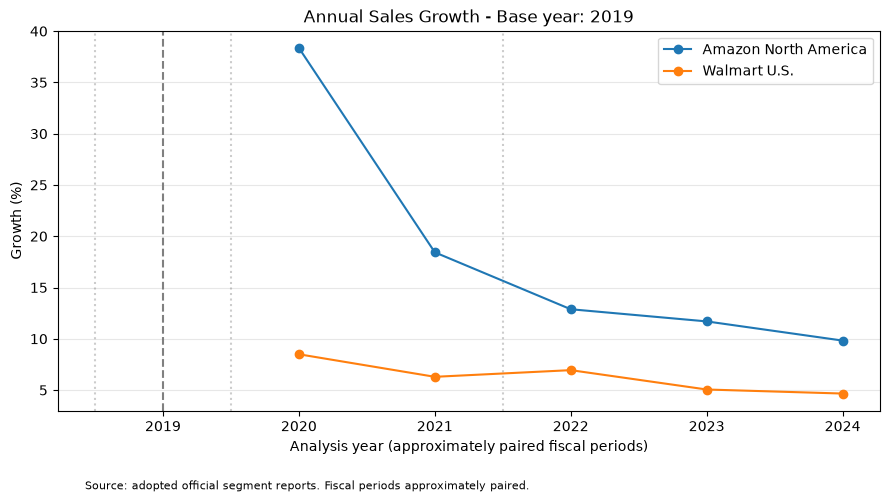

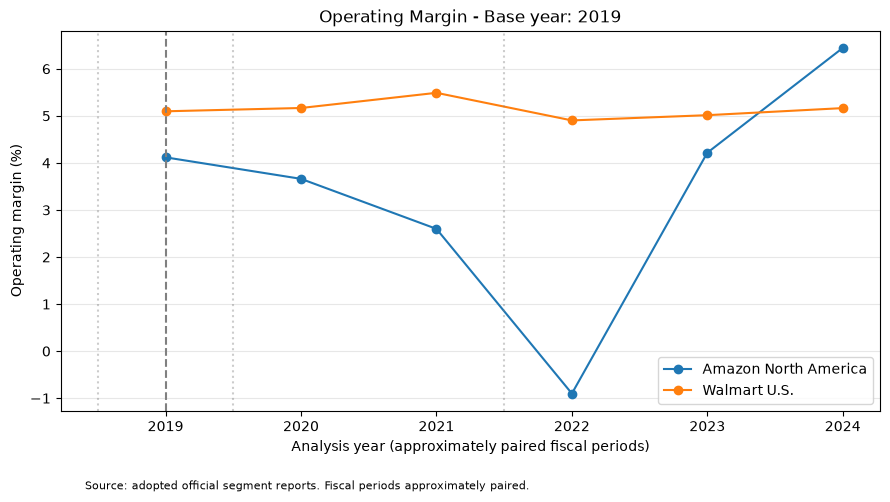

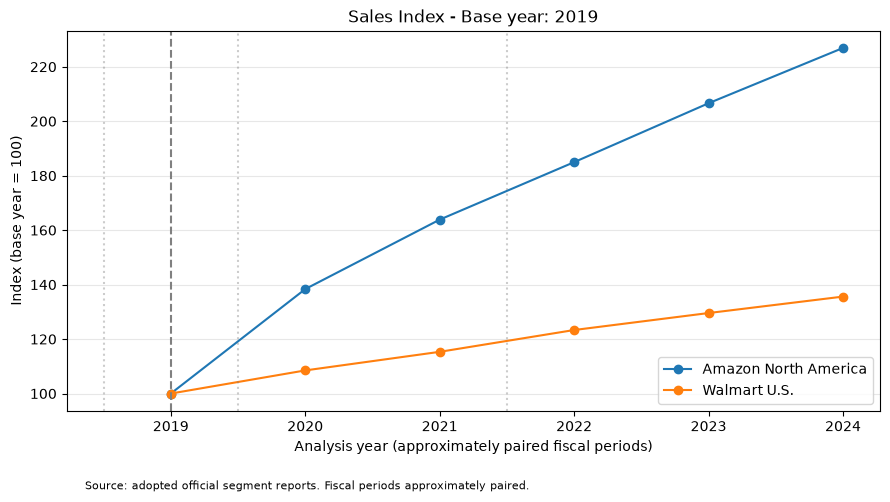

In [13]:
# Cell 02: Create the Three Charts

metrics_df = database.read("annual_metrics")
stage_df = database.read("stage_summary")
report_builder = ReportBuilder(config, OUTPUT_DIRECTORY)

for column, title, ylabel in config.charts:
    report_builder.plot_chart(metrics_df, column, title, ylabel)


In [14]:
# Cell 03: Save the Research Report

report_path = report_builder.write_report(metrics_df, stage_df)
print(f"Report saved: {report_path}")
print(f"Database saved: {database.database_path}")
print("All four modules are complete.")


Report saved: retail_simple_output/research_report.html
Database saved: retail_simple_output/retail_comparison.sqlite
All four modules are complete.
